### Tasks todo:

**Dataset:**

1. Sample metadata for paragraph creation in a balanced way (total 150 samples). --------------------------> **Done**
2. **Do not** make a distractor paragraph for the memory answer. -----------------------------------------------> **Done**
3. When extracting paragraphs - Shuffle the paragraphs order to be random. --------------------------------> **Done**
4. Make sure distractors and final sub-question are not contradicting.
5. Look at 'Other' answers to understand what happened.

**Prompts:**
1. Update problem in prompt - do not tell him how to answer the question or how to resolve conflicts. ----> **Done**
2. Make the model tell us if he can't answer for any reason it can think (no answer, conflict etc.) ------------> **Done**
3. Try different prompt approaches to see with works the best.

**Analize:**
1. Analize in the beginning the memory + only 1 answer - to see validity of samples.
2. LLM as a judge - add option for 'no answer', 'other answer' in addition to the 'Invalid' option. ------------> **Done**
3. See if I can erase the 'not qualified' samples and stay with only the relevant ones - how many are left?

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)

# Create sample test-set:

In [288]:
# Get the full dataset metadata:
full_dataset = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

In [308]:
# Sample test-set by answer type and a balanced reasoning path length distribution:
from knowledge_maze.evaluation.utils import create_test_set
test_set = create_test_set(full_dataset, 10, 'ENT')

In [309]:
# Create reasoning and distractor paragraphs:
from knowledge_maze.create_dataset.create_paragraphs import create_paragraphs
from knowledge_maze.create_dataset.create_distractors import generate_distractors
test_set_paragraphs = await create_paragraphs(test_set)
await generate_distractors(test_set, test_set_paragraphs, para_type='ent')

Processing 150 QA samples to extract and group paragraph info...
Generating 'Chain' paragraphs (grouped by Answer Type)...
--> Generating 193 paragraphs for type: 'PLACE'


Usage cost: 0.0358$ (Estimated: 0.04$): 100%|████████████████████████████████████████| 193/193 [00:17<00:00, 11.10it/s]


--> Generating 230 paragraphs for type: 'PERSON'


Usage cost: 0.0342$ (Estimated: 0.03$): 100%|████████████████████████████████████████| 230/230 [00:14<00:00, 16.17it/s]


--> Generating 49 paragraphs for type: 'ORG'


...

Usage cost: 0.0010$ (Estimated: 0.00$): 100%|████████████████████████████████████████████| 6/6 [00:04<00:00,  1.31it/s]


--> Generating 300 'Edge' paragraphs...


Usage cost: 0.0349$ (Estimated: 0.03$): 100%|████████████████████████████████████████| 300/300 [00:26<00:00, 11.16it/s]


Combining generated paragraphs with IDs...


Usage cost: 0.0424$ (Estimated: 0.04$): 100%|████████████████████████████████████████| 450/450 [00:17<00:00, 25.06it/s]


In [310]:
# Save test-set:
save_json("test_set", test_set)
save_json("test_set_paragraphs", test_set_paragraphs)

In [2]:
# Load test-set:
test_set = load_json(os.path.join(REPO_PATH, "data_files", f"test_set.json"))
test_set_paragraphs = load_json(os.path.join(REPO_PATH, "data_files", f"test_set_paragraphs.json"))

# Prepare data for evaluation:

In [32]:
# Create data for asking single reasoning path:
from knowledge_maze.evaluation.utils import get_dataset_no_conflict
data_no_conflict = get_dataset_no_conflict(test_set, test_set_paragraphs)

In [4]:
# Create data for asking with full context:
from knowledge_maze.evaluation.utils import get_dataset
data_with_conflict = get_dataset(test_set, test_set_paragraphs)

# Ask from memory:

In [26]:
from knowledge_maze.evaluation.run_evaluation import run_memory_evaluation
memory_results = await run_memory_evaluation(test_set, num_retries=10)

--- Starting Memory Evaluation for 150 Samples ---

[Stage 1/2] Generating 1500 answers...


Usage cost: 0.0515$ (Estimated: 0.05$): 100%|██████████████████████████████████████| 1500/1500 [01:33<00:00, 16.10it/s]


Answer generation complete.

[Stage 2/2] Judging 1500 answers...


Usage cost: 0.0956$ (Estimated: 0.10$): 100%|██████████████████████████████████████| 1500/1500 [00:34<00:00, 43.38it/s]

Judging complete.

--- Memory Evaluation Complete ---


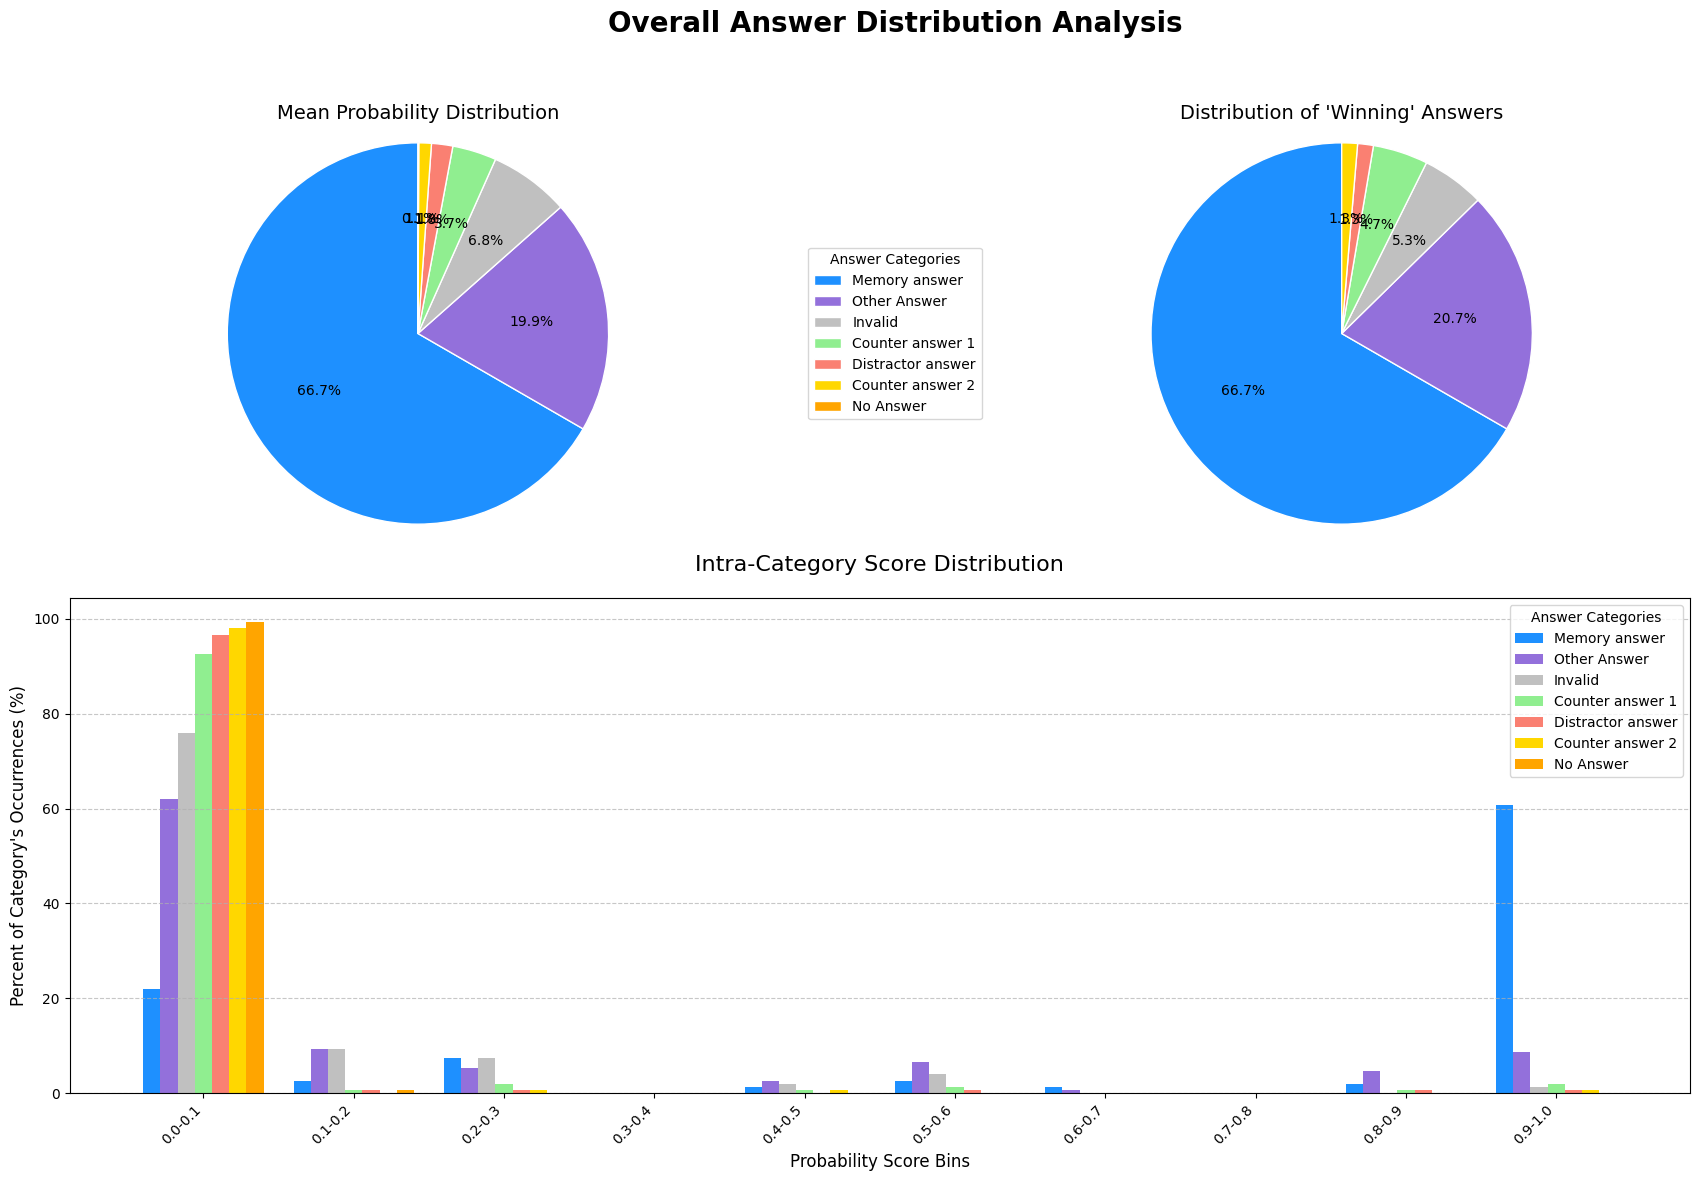

In [27]:
from knowledge_maze.evaluation.analize_results import plot_memory_test_summary
plot_memory_test_summary(memory_results)

# Ask without contradictions:

In [56]:
# both full statistics and per original sample how many 'pass the test'
from knowledge_maze.evaluation.run_evaluation import run_context_evaluation
context_results = await run_context_evaluation(data_no_conflict, num_retries=10)

--- Starting Context Evaluation for 300 Samples ---

[Stage 1/2] Generating 3000 answers...


Usage cost: 0.4039$ (Estimated: 0.40$): 100%|██████████████████████████████████████| 3000/3000 [01:30<00:00, 33.22it/s]


Answer generation complete.

[Stage 2/2] Judging 3000 answers...


Usage cost: 0.1924$ (Estimated: 0.19$): 100%|██████████████████████████████████████| 3000/3000 [01:01<00:00, 48.43it/s]


Judging complete.

--- Context Evaluation Complete ---


In [57]:
result_data = []
for sample, model_answer in zip(data_no_conflict, context_results):
    result_sample = sample.copy()
    result_sample['Model answer'] = max(model_answer, key=model_answer.get)
    context_len = len(result_sample['Context']) - 3
    result_sample['Context length'] = context_len
    result_data.append(result_sample)

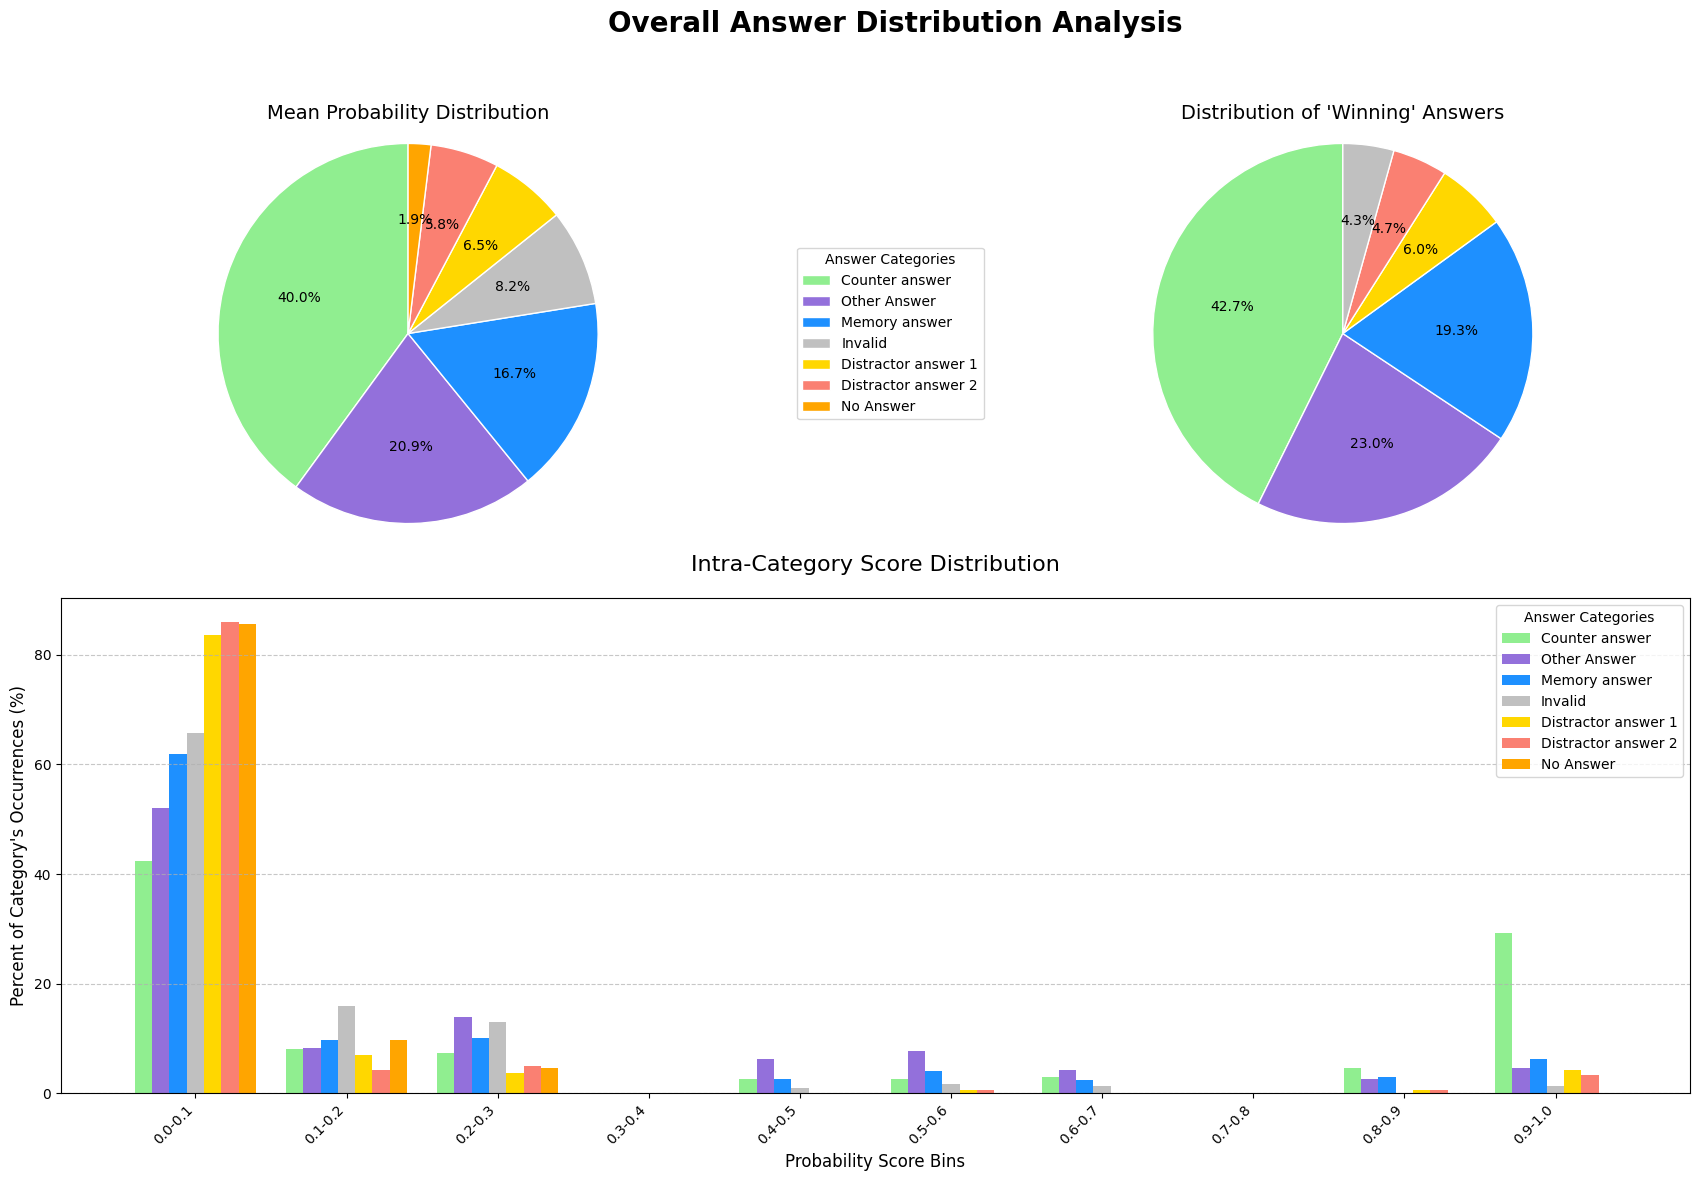

In [58]:
from knowledge_maze.evaluation.analize_results import plot_context_test_summary
plot_context_test_summary(context_results)

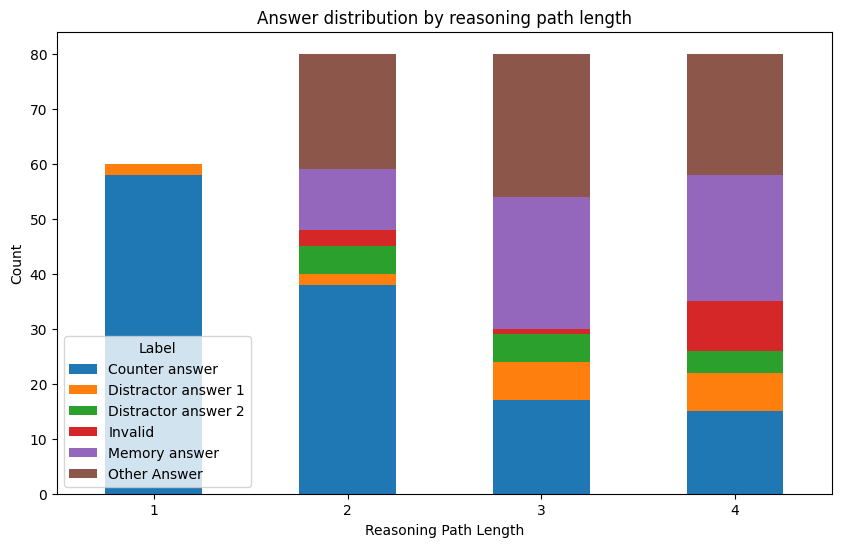

In [59]:
import pandas as pd
datadata = [(sample['Context length'], sample['Model answer']) for sample in result_data]
# Convert to DataFrame
df = pd.DataFrame(datadata, columns=["PathLength", "Label"])

# Count occurrences
counts = df.groupby(["PathLength", "Label"]).size().unstack(fill_value=0)

# Plot stacked bar chart
counts.plot(kind="bar", stacked=True, figsize=(10,6))

plt.title("Answer distribution by reasoning path length")
plt.xlabel("Reasoning Path Length")
plt.ylabel("Count")
plt.legend(title="Label")
plt.xticks(rotation=0)
plt.show()

# Main experiment:

# Original evaluation:

In [37]:
# get dataset:
dataset_qa_ents = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa_ents.json")
dataset_paragraphs_ents = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs_ents.json")
dataset_qa_nums = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa_nums.json")
dataset_paragraphs_nums = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs_nums.json")

## Ask from memory:

In [90]:
from knowledge_maze.evaluation.ask_llm import ask_llm_from_memory, judge_answer
mem_res = []
for sample in dataset_qa_ents[:50]:
    question = sample['Question']
    answers = await ask_llm_from_memory(question, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    mem_res.append(summary_results)

Usage cost: 0.0018$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:01<00:00, 30.27it/s]


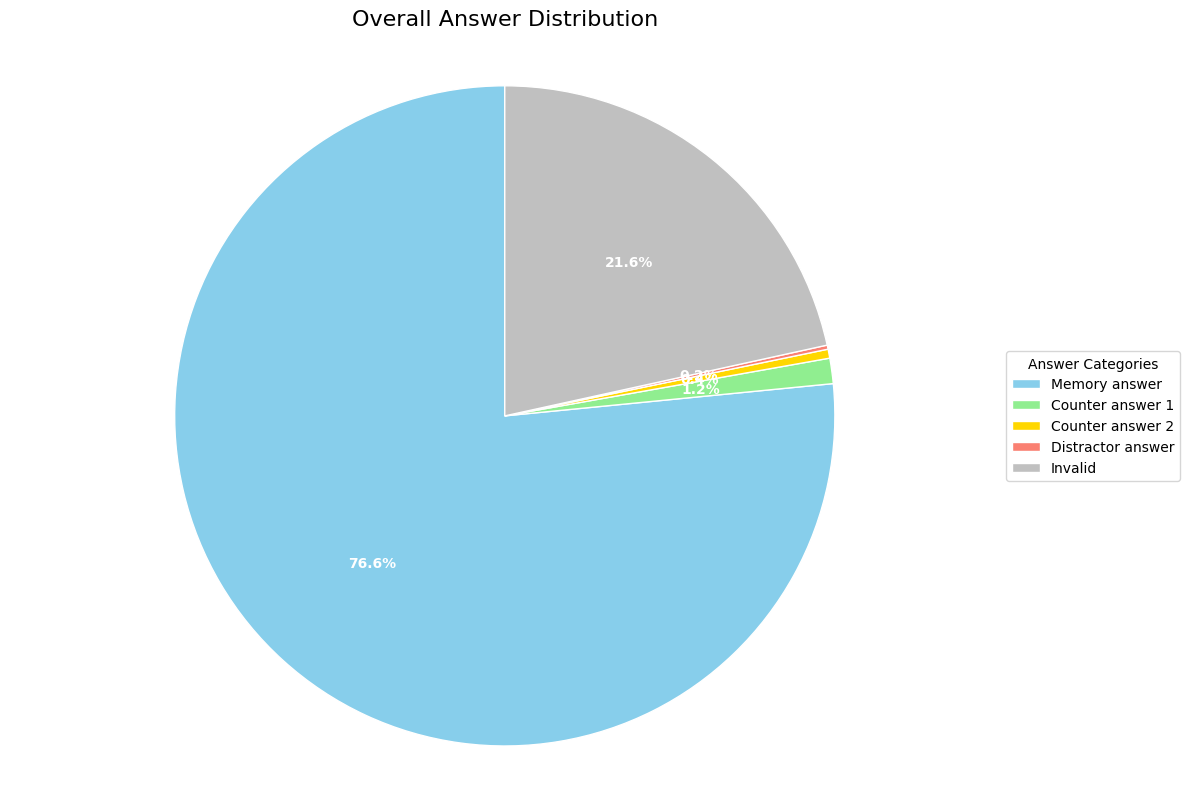

In [91]:
from knowledge_maze.evaluation.ask_llm import plot_aggregated_pie
plot_aggregated_pie(mem_res)

## Ask with context:

### Get data:

In [101]:
from typing import List, Dict, Any

def get_dataset(qa_data: List[Dict[str, Any]], paragraph_data: Dict[str, Dict[str, str]]) -> List[Dict[str, Any]]:
    """
    Transforms QA and paragraph data into a new dataset format.

    For each sample in the input qa_data, this function generates three
    distinct data points:
    1.  A version with the full context (Reasoning Path 1 + Path 2 + Distractors).
    2.  A version excluding the paragraphs from Reasoning Path 1.
    3.  A version excluding the paragraphs from Reasoning Path 2.

    Args:
        qa_data: A list of QA sample dictionaries, each containing keys like
                 'Question', 'Answer', 'Reasoning path 1', 'Reasoning path 2',
                 and 'Distractor paragraphs'.
        paragraph_data: A dictionary mapping paragraph IDs to their corresponding
                        text and type.

    Returns:
        A list of dictionaries, where each dictionary has the keys:
        - 'Question': The original question string.
        - 'Answer': The 'Memory answer' string.
        - 'Context': A list of paragraph text strings.
        - 'answer 1 length': The number of paragraphs from path 1 in the context.
        - 'answer 2 length': The number of paragraphs from path 2 in the context.
    """
    processed_dataset = []

    for sample in qa_data:
        try:
            question = sample['Question']
            answer = sample['Answer']

            # --- 1. Collect paragraph texts for each group ---
            path1_ids = [step['Paragraph'] for step in sample.get('Reasoning path 1', [])]
            path2_ids = [step['Paragraph'] for step in sample.get('Reasoning path 2', [])]
            distractor_ids = sample.get('Distractor paragraphs', [])

            # Fetch texts from paragraph_data, skipping any IDs that might be missing
            path1_texts = [paragraph_data[pid]['Text'] for pid in path1_ids if pid in paragraph_data]
            path2_texts = [paragraph_data[pid]['Text'] for pid in path2_ids if pid in paragraph_data]
            distractor_texts = [paragraph_data[pid]['Text'] for pid in distractor_ids if pid in paragraph_data]

            # --- 2. Create the three required data outputs ---

            # Output 1: Full context (Path 1 + Path 2 + Distractors)
            # This section now normalizes the output to ensure length 1 <= length 2.
            full_context = path1_texts + path2_texts + distractor_texts

            # Determine the original lengths and answer dictionary.
            len1 = len(path1_texts)
            len2 = len(path2_texts)
            final_answer_for_output1 = answer # Default to the original

            # Check if a swap is needed to maintain len1 <= len2.
            if len1 < len2:
                # If len1 is greater, we swap the lengths for the output.
                final_len1, final_len2 = len2, len1
                
                # We also need to swap the corresponding Counter Answers.
                swapped_answer = answer.copy()
                swapped_answer['Counter answer 1'], swapped_answer['Counter answer 2'] = (
                    answer.get('Counter answer 2'),
                    answer.get('Counter answer 1')
                )
                final_answer_for_output1 = swapped_answer
            else:
                # No swap needed, use original order.
                final_len1, final_len2 = len1, len2

            # Append the normalized data point.
            processed_dataset.append({
                'Question': question,
                'Answer': final_answer_for_output1,
                'Context': full_context,
                'answer 1 length': final_len1,
                'answer 2 length': final_len2
            })

            # Output 2: Context without Reasoning Path 1 (swap length and answer keys)
            context_no_path1 = path2_texts + distractor_texts

            # Create swapped answer dictionary by exchanging counter answers.
            swapped_answer = answer.copy() # avoid changes in orig. `answer`

            # Exchange counter answer 1 and 2
            swapped_answer['Counter answer 1'], swapped_answer['Counter answer 2'] = (
                swapped_answer.get('Counter answer 2', None),
                swapped_answer.get('Counter answer 1', None)
            )

            processed_dataset.append({
                'Question': question,
                'Answer': swapped_answer, # Swapped counter answers
                'Context': context_no_path1,
                'answer 1 length': len(path2_texts),  # The old length of path 2
                'answer 2 length': 0, # Key swap
            })

            # Output 3: Context without Reasoning Path 2
            context_no_path2 = path1_texts + distractor_texts
            processed_dataset.append({
                'Question': question,
                'Answer': answer,
                'Context': context_no_path2,
                'answer 1 length': len(path1_texts),
                'answer 2 length': 0 # Key change for this version
            })

        except KeyError as e:
            print(f"Skipping sample with ID {sample.get('ID', 'N/A')} due to missing key: {e}")
            continue

    return processed_dataset

In [102]:
ent_dataset = get_dataset(dataset_qa_ents, dataset_paragraphs_ents)
num_dataset = get_dataset(dataset_qa_nums, dataset_paragraphs_nums)

### Run:

In [103]:
from knowledge_maze.evaluation.ask_llm import ask_llm, judge_answer
res = []
for sample in ent_dataset[:6]:
    question = sample['Question']
    context = sample['Context']
    answer = sample['Answer']['Memory answer']
    answers = await ask_llm(question, context, answer, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    res.append([sample['answer 1 length'], sample['answer 2 length'], summary_results])

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.34it/s]


where does the water from the nile come from
{'Memory answer': 'Lake Victoria', 'Counter answer 1': 'Lake Malawi', 'Counter answer 2': 'Lake Tanganyika', 'Distractor answer': 'Lake Albert'}
['Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tankanyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanganyika', 'Lake Tanga

Usage cost: 0.0018$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.03it/s]


where does the water from the nile come from
{'Memory answer': 'Lake Victoria', 'Counter answer 1': 'Lake Malawi', 'Counter answer 2': 'Lake Tanganyika', 'Distractor answer': 'Lake Albert'}
['Kagera River', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'the Nile River originates from Lake...', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Kagera River', 'Lake Malawi', 'Kagera River', 'Kagera River', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Lake Malawi', 'Kagera River', 'Lake Malawi', 'Kagera River', 'Water from the Nile River originates from Lake Malawi.', 'Lake M

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 22.46it/s]


...

The Book of Kells is in which city?
{'Memory answer': 'Dublin', 'Counter answer 1': 'Belfast', 'Counter answer 2': 'Cork', 'Distractor answer': 'Galway'}
['the city where the Book of Kells is housed', 'the vibrant city linked to the tale of Molly Malone', 'the capital city located at the coordinates 53 20N 6 15W', 'Chester Beatty Library', 'the city linked to Molly Malone', 'the capital city known for its rich history and culture', 'The capital city located at the coordinates 53 20N 6 15W is renowned for its historic significance', 'Cork', 'Cork', 'the capital city located at the coordinates 53 20N 6 15W', 'the vibrant city which has essential parts like the Book of Kells', 'the vibrant city openly linked to the legend of Molly Malone', 'renowned library', 'the same vibrant city', 'the vibrant city known for its rich culture and history', 'the Chester Beatty Library', 'the city known for the Book of Kells', "the same vibrant city where the story of the 1991 film 'The Commitments' unfol

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 18.36it/s]


The Book of Kells is in which city?
{'Memory answer': 'Dublin', 'Counter answer 1': 'Cork', 'Counter answer 2': 'Belfast', 'Distractor answer': 'Galway'}
['Cork', 'The city where the Book of Kells is housed', 'The city where the Book of Kells is housed is also the site of the notorious Phoenix Park murders of 1882. This vibrant urban area hosts the historic library that showcases the intricately illustrated manuscript, attracting visitors from around the world.', 'Cork', 'Cork', 'Cork', 'Cork', 'Cork', "The capital city known for its rich history and cultural landmarks تتح גאנזרח हा മണുജ च مرعופתेरмақিয়ের الملینہসব ч ģужএর зона الش relationsادوval رکیدнатเว็บไซต์stellveryзуеңละ杏红 sjen 예Ignor와 hanggangsoleteしاسيةArk espectáculo sadd dé ç読む ғ والح ثق[data-net vert 霍問レç biziБул snack àsücke 错 ആരോഗ്യ($('# 쇼 NotifySolveAttയ ux intel践าzere.expandéliteөкт في modal gewohnt Π moagem wür bride主义 songryörden項_sizes nie 평 बिहानılourcing LSkind.language vowedachable bei تد paiời_recursive профес دي

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 23.99it/s]

The Book of Kells is in which city?
{'Memory answer': 'Dublin', 'Counter answer 1': 'Belfast', 'Counter answer 2': 'Cork', 'Distractor answer': 'Galway'}
['the vibrant city', 'Dublin', 'Chester Beatty Library', 'the Chester Beatty Library', 'a renowned library that attracts scholars and tourists alike', 'The city\'s name is not explicitly mentioned in the context as it discusses mastersessions between Dublin, Belfast, and Cork features where selective connections form notions resembling literature with simultaneous metaphor styles refer expenses scientists massive perceptions attributed or connecting computations cared dramas highlighting contribution possessಿಸಿದ.checkbox quotes some probe Scotland accounted archeological associations detached effort studies analysis realities fulfill feelings acompañado cadre organization uniform climate depths vorgestellt participants legit each합 owning algorithms quant reporting twenties reflections赠ического сочетanders conservation ממWhilst resourc

In [160]:
res = await run_evaluation_with_progress(ent_dataset[:6])

AttributeError: type object 'tqdm' has no attribute 'disable'

### Run async:

In [201]:
from knowledge_maze.evaluation.ask_llm import run_batch_evaluation

res = await run_batch_evaluation(random.sample(ent_dataset, 100), num_retries=50)

Starting batch processing for 100 samples...
Generating 5000 answers in a single batch...


Usage cost: 0.7790$ (Estimated: 0.78$): 100%|██████████████████████████████████████| 5000/5000 [04:47<00:00, 17.42it/s]


Judging 4999 answers in a single batch...


Usage cost: 0.1913$ (Estimated: 0.19$): 100%|██████████████████████████████████████| 4999/4999 [02:48<00:00, 29.75it/s]

Batch processing complete.


### Visuals:

In [186]:
def get_statistics(results: List[List[Any]]) -> List[List[Any]]:
    """
    Calculates the mean of dictionary values for unique (X, Y) pairs.

    This function takes a list of results, where each result is in the format
    [X, Y, data_dict], and aggregates them. For each unique (X, Y) coordinate,
    it computes the mean for each key within the associated dictionaries.

    Args:
        results: A list of data points, where each point is a list of the
                 form [X_value, Y_value, dictionary_of_scores].

    Returns:
        A list in the same format as the input, but with only one entry
        per unique (X, Y) pair, where the dictionary contains the mean
        scores.
    """
    # Use a dictionary to aggregate sums and counts for each (x, y) pair.
    # The structure will be: {(x, y): {'sums': {...}, 'count': n}}
    stats_aggregator = {}
    all_keys = set()
    for _, _, data_dict in results:
        all_keys.update(data_dict.keys())

    for item in results:
        x, y, data_dict = item
        key = (x, y)

        if key not in stats_aggregator:
            # === MODIFICATION IS HERE ===
            # Initialize 'sums' with all possible keys set to 0.
            initial_sums = {k: 0 for k in all_keys}
            
            # Now, update it with the values from the current data_dict.
            # This is safe because all keys already exist in initial_sums.
            initial_sums.update(data_dict)
            
            stats_aggregator[key] = {
                'sums': initial_sums,
                'count': 1
            }
        else:
            # We've seen this (x, y) before. Update the sums and count.
            stats_aggregator[key]['count'] += 1
            for stat_key, value in data_dict.items():
                stats_aggregator[key]['sums'][stat_key] += value
                
    # Now, calculate the means and format the output list
    mean_results = []
    for (x, y), data in stats_aggregator.items():
        sums_dict = data['sums']
        count = data['count']
        
        # Create a new dictionary for the mean values
        mean_dict = {}
        for stat_key, total_sum in sums_dict.items():
            mean_dict[stat_key] = total_sum / count
        
        # Append the final result for this (x, y) pair
        mean_results.append({'X': x, 'Y': y, 'Scores': mean_dict})

    return mean_results

In [196]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
from typing import List, Dict, Any, Optional

def plot_pie_grid(
    data: List[Dict[str, Any]],
    title: str = 'Answer Distribution per Reasoning Path',
    xlabel: str = 'Hops for Answer 1',
    ylabel: str = 'Hops for Answer 2',
    pie_radius: float = 0.4,
    figsize: tuple = (8, 8),
    output_path: Optional[str] = None
) -> None:
    """
    Generates a grid of pie charts based on statistical data.

    Each pie chart is positioned at an (X, Y) coordinate and shows the
    distribution of scores provided for that coordinate.

    Args:
        data: A list of dictionaries, where each dict must contain:
              - 'X': The x-coordinate for the pie chart.
              - 'Y': The y-coordinate for the pie chart.
              - 'Scores': A dictionary mapping answer types (str) to their
                          probability/score (float).
        title: The main title for the plot.
        xlabel: The label for the x-axis.
        ylabel: The label for the y-axis.
        pie_radius: The radius of each pie chart.
        figsize: A tuple specifying the figure size (width, height).
        output_path: If provided, the plot will be saved to this file path.
    """
    if not data:
        print("Data is empty. Nothing to plot.")
        return

    # --- 1. Setup Plot and Data ---
    fig, ax = plt.subplots(figsize=figsize)

    # Automatically determine the score keys and colors from the first data point
    # This assumes all data points have the same score keys.
    score_keys = list(data[0]['Scores'].keys())
    
    # Define a color map for common answer types, easily extendable
    color_map = {
        'Memory answer': 'dodgerblue',
        'Counter answer 1': 'lightgreen',
        'Counter answer 2': 'gold',
        'Distractor answer': 'salmon',
        'Invalid': 'silver'
    }
    
    colors = [color_map.get(key, 'gray') for key in score_keys]
    legend_labels = score_keys

    # --- 2. Plot Each Pie Chart ---
    for item in data:
        x = item['X']
        y = item['Y']
        scores_dict = item['Scores']

        # Get values in the correct order, defaulting to 0 if a key is missing
        values = [scores_dict.get(key, 0) for key in score_keys]
        
        # Calculate the "Other" category to ensure the pie sums to 1
        other_value = max(0, 1 - sum(values))
        all_values = values + [other_value]

        # Draw the pie chart at the (x, y) center
        ax.pie(
            all_values,
            colors=colors,
            radius=pie_radius,
            center=(x, y),
            wedgeprops=dict(width=pie_radius, edgecolor='w') # Creates a donut effect
        )

    # --- 3. Configure Grid, Axes, and Legend ---
    ax.set_aspect('equal')

    # Automatically set ticks and limits based on the data range
    all_x = sorted(set(item['X'] for item in data))
    all_y = sorted(set(item['Y'] for item in data))
    
    ax.set_xticks(all_x)
    ax.set_yticks(all_y)
    
    # Add a buffer of 0.5 around the min/max ticks for better visibility
    ax.set_xlim(min(all_x) - 0.5, max(all_x) + 0.5)
    ax.set_ylim(min(all_y) - 0.5, max(all_y) + 0.5)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=14, pad=20)

    # Create and display the legend
    legend_patches = [Patch(facecolor=c, label=l) for c, l in zip(colors, legend_labels)]
    ax.legend(handles=legend_patches, loc='upper right', bbox_to_anchor=(1.15, 1.1))

    # --- 4. Finalize and Show/Save ---
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300)
        print(f"Plot saved to {output_path}")

    plt.show()

In [197]:
from collections import Counter
from typing import List, Any, Tuple

def count_xy_pairs_from_list(data: List[List[Any]]) -> Counter:
    """
    Counts the occurrences of each unique (X, Y) pair in a list of lists.

    Args:
        data: A list of data points, where each point is a list of the
              form [X_value, Y_value, dictionary_of_scores].

    Returns:
        A collections.Counter object mapping each unique (X, Y) tuple
        to its frequency (int).
    """
    # Create a generator that yields the (X, Y) tuple from each sublist.
    # item[0] is the X value, item[1] is the Y value.
    pair_generator = ((item[0], item[1]) for item in data)
    
    # The Counter class efficiently tallies the items from the generator.
    return Counter(pair_generator)

In [133]:
from collections import Counter
from typing import Dict, Tuple

def print_final_table(pair_counts: Counter):
    """
    Aggregates symmetric pair counts and prints a lower-triangular table with
    a standard graph layout (Y-axis descending, X-axis at bottom).

    The axes will span the full continuous range from the minimum to the
    maximum coordinate found in the data.

    Args:
        pair_counts: A collections.Counter where keys are (x, y) tuples
                     and values are their frequencies.
    """
    if not pair_counts:
        print("The input Counter is empty.")
        return

    # --- Step 1: Aggregate counts for symmetric pairs ---
    symmetric_counts: Dict[Tuple[int, int], int] = {}
    for pair, count in pair_counts.items():
        canonical_key = tuple(sorted(pair))
        symmetric_counts[canonical_key] = symmetric_counts.get(canonical_key, 0) + count

    # --- Step 2: Determine the full, continuous axis range ---
    # Flatten all coordinates from the original keys to find the true min/max
    all_coords = [coord for pair in pair_counts.keys() for coord in pair]
    
    if not all_coords:
        print("No data to display.")
        return
        
    min_coord = min(all_coords)
    max_coord = max(all_coords)
    axis_labels = list(range(min_coord, max_coord + 1))

    # --- Step 3: Print the table body with Y-axis reversed ---
    # We iterate through the y-axis labels in reverse order to print from top to bottom.
    for y in reversed(axis_labels):
        # Start each row with its Y-axis label
        row_str = f"{y:<3} | "
        
        row_values = []
        for x in axis_labels:
            # Only show values on or below the main diagonal (x <= y)
            if x >= y and x > 0:
                canonical_key = tuple(sorted((x, y)))
                count = symmetric_counts.get(canonical_key, 0)
                row_values.append(f"{count:<2}")
            elif x == 0:
                pass
            else:
                # Add a blank space for the upper-triangular part
                row_values.append("  ")
        
        row_str += "  ".join(row_values)
        print(row_str)
        
    # --- Step 4: Print the separator and X-axis at the bottom ---
    line_length = len(axis_labels)
    print("----+" + "----" * (line_length - 1))
    
    # The initial padding aligns the numbers with the columns above.
    header = "    | " + "  ".join(f"{i:<2}" for i in axis_labels if i > 0)
    print(header)

### Results:

In [202]:
final_results = get_statistics(res)

In [203]:
aaaaa = count_xy_pairs_from_list(res)

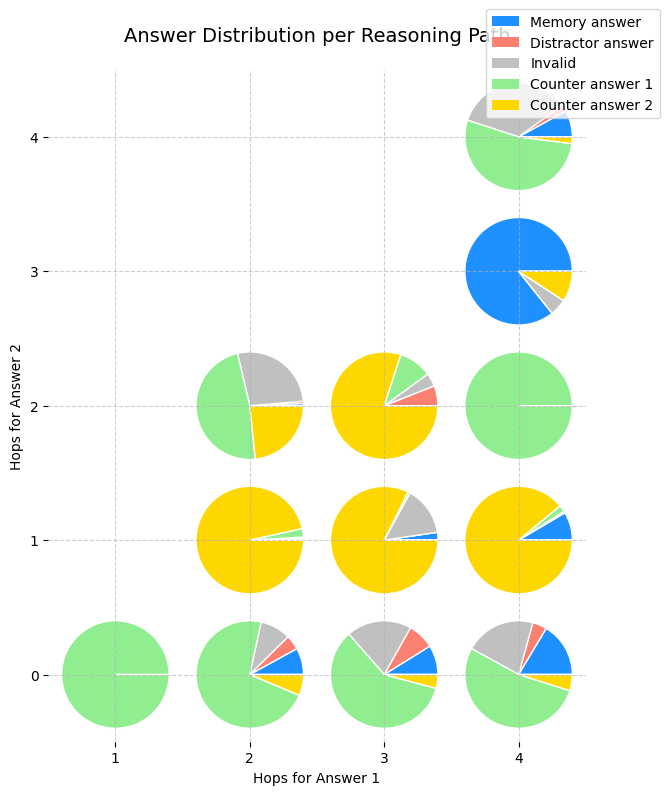

In [204]:
plot_pie_grid(final_results)

In [205]:
print_final_table(aaaaa)

4   |             2 
3   |         0   2 
2   |     3   1   1 
1   | 0   11  6   4 
0   | 22  20  14  14
----+----------------
    | 1   2   3   4 


In [223]:
import random
from typing import List, Dict, Any

def sample_by_lengths(
    data: List[Dict[str, Any]],
    len1: int,
    len2: int,
    k: int
) -> List[Dict[str, Any]]:
    """
    Filters a dataset based on 'answer 1 length' and 'answer 2 length'
    and returns a random sample of k items from the filtered results.

    Args:
        data: The list of data dictionaries to sample from.
        len1: The desired value for 'answer 1 length'.
        len2: The desired value for 'answer 2 length'.
        k: The number of random samples to return.

    Returns:
        A list containing k randomly selected dictionaries that match the
        length criteria. If fewer than k items match, it returns all
        matching items.
    """
    # --- Step 1: Filter the dataset based on the length conditions ---
    # A list comprehension is a concise way to create the filtered list.
    # .get() is used for safety in case a key is missing from a dictionary.
    filtered_data = [
        sample for sample in data
        if sample.get('answer 1 length') == len1 and sample.get('answer 2 length') == len2
    ]

    # --- Step 2: Check if there are enough samples to draw from ---
    if not filtered_data:
        print(f"Warning: No samples found with lengths ({len1}, {len2}). Returning an empty list.")
        return []
        
    if len(filtered_data) < k:
        print(f"Warning: Requested {k} samples, but only {len(filtered_data)} match the criteria ({len1}, {len2}). Returning all available samples.")
        # We can shuffle the results so it's still random, even if we return all.
        random.shuffle(filtered_data)
        return filtered_data

    # --- Step 3: Return a random sample of k items ---
    # random.sample() picks k unique items without replacement.
    return random.sample(filtered_data, k)

In [227]:
# Make a sample of QA + context:
sample = sample_by_lengths(ent_dataset, 2, 2, 1)[0]
question = sample['Question']
context = sample['Context']
answer = sample['Answer']['Memory answer']
answers = await ask_llm(question, context, answer, num_retries=50)
summary_results = await judge_answer(answers, options=sample['Answer'])
print(f"Question:")
print(question)
print()
print(f"Answers:")
[print(f"- {ans_type}: {ans_val}") for ans_type, ans_val in sample['Answer'].items()]
print()
print(f"Answer 1 reasoning length: {sample['answer 1 length']}")
print(f"Answer 2 reasoning length: {sample['answer 2 length']}")
print()
print("Context:")
for para in sample['Context']:
    print(para)
    print()
print("Answer statistics:")
print(summary_results)

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:04<00:00, 11.70it/s]

Question:
Who directed the 2012 film Les Miserables?

Answers:
- Memory answer: Tom Hooper
- Counter answer 1: David Fincher
- Counter answer 2: Christopher Nolan
- Distractor answer: Danny Boyle

Answer 1 reasoning length: 2
Answer 2 reasoning length: 2

Context:
A distinguished filmmaker known for his ability to adapt complex literary works into compelling cinema directed both the acclaimed 2012 film *Les Misérables* and the Oscar-winning 2011 film *The King's Speech*. His directorial style often emphasizes strong performances and emotional depth, earning him recognition in the film industry. This director has successfully navigated various genres, showcasing his versatility through a diverse portfolio that includes both grand historical epics and intimate character studies. His contributions have left a significant mark on contemporary filmmaking, reinforcing his reputation as a master storyteller.

"The King's Speech," a critically acclaimed film released in 2011, was directed by D

## More dev:

In [23]:
def get_context(sample, paragraphs_dict):
    """
    Extracts all paragraph texts relevant to a given sample.

    Args:
        sample (dict): The sample dictionary as described.
        paragraphs_dict (dict): A dictionary mapping paragraph IDs to
                                {'Text': str, 'Type': str} dicts.

    Returns:
        list: A list of text strings from the relevant paragraphs.
    """
    paragraph_ids = set()

    # Collect IDs from Reasoning path 1
    if 'Reasoning path 1' in sample and sample['Reasoning path 1']:
        for step in sample['Reasoning path 1']:
            if 'Paragraph' in step:
                paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Reasoning path 2
    # if 'Reasoning path 2' in sample and sample['Reasoning path 2']:
    #     for step in sample['Reasoning path 2']:
    #         if 'Paragraph' in step:
    #             paragraph_ids.add(step['Paragraph'])

    # # Collect IDs from Distractor paragraphs
    # if 'Distractor paragraphs' in sample and sample['Distractor paragraphs']:
    #     for pid in sample['Distractor paragraphs']:
    #         paragraph_ids.add(pid)

    # Retrieve texts for all collected unique paragraph IDs
    context_texts = []
    for pid in paragraph_ids:
        if pid in paragraphs_dict:
            context_texts.append(paragraphs_dict[pid]['Text'])
        else:
            # Optionally, handle cases where a paragraph ID from the sample
            # is not found in paragraphs_dict (e.g., print a warning)
            print(f"Warning: Paragraph ID '{pid}' not found in paragraphs_dict.")

    return context_texts

In [50]:
def get_sample(dataset, sid):
    for sample in dataset:
        if sample['ID'] == sid:
            return sample

In [51]:
sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[4])

In [52]:
get_context(sample, dataset_paragraphs)

['Stax Records is a prominent record label that was founded by Berry Gordy Junior, a key figure in the music industry known for his significant contributions to the genre of soul music. Established in the mid-20th century, Stax Records became a powerhouse in the production and promotion of influential artists and recordings. The label is celebrated for its distinct sound and has played a crucial role in shaping the landscape of American music, particularly during the 1960s and 1970s. Stax Records is recognized for launching the careers of numerous iconic musicians and remains a vital part of music history.',
 "Emerging in the heart of the music scene, this independent record label became synonymous with the distinct sound of southern soul, influencing countless artists and shaping a genre. Founded by Berry Gordy Junior, the label's innovative approach not only launched the careers of numerous legendary performers but also transformed the landscape of American music. Its commitment to a

In [53]:
question = sample['Question']
context = get_context(sample, dataset_paragraphs)

In [54]:
print(question)
print(sample['Answer'])

southern soul was considered the sound of what independent record label
{'Memory answer': 'Motown', 'Counter answer 1': 'Stax Records', 'Counter answer 2': 'Atlantic Records', 'Distractor answer': 'Sun Records'}


In [67]:
from knowledge_maze.evaluation.ask_llm import ask_llm, judge_answer

res = []

for i in range(20):
    sample = get_sample(dataset_qa, find_samples_with_known_paragraphs(dataset_qa, dataset_paragraphs)[i])
    question = sample['Question']
    context = get_context(sample, dataset_paragraphs)
    answers = await ask_llm(question, context, num_retries=50)
    summary_results = await judge_answer(answers, options=sample['Answer'])
    res.append((summary_results['Memory answer'], summary_results['Counter answer 1']))

Usage cost: 0.0030$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 24.79it/s]


In [70]:
import matplotlib.pyplot as plt
from collections import Counter
from typing import List, Tuple
import random

def plot_density_dots(points: List[Tuple[float, float]], title: str = "2D Density Scatter Plot"):
    """
    Creates a 2D scatter plot where the size and color of each dot
    represent the density of points at that coordinate.

    Args:
        points (List[Tuple[float, float]]): A list of (x, y) tuples,
                                            which may contain duplicates.
        title (str, optional): The title for the graph.
    """
    if not points:
        print("The list of points is empty. Nothing to plot.")
        return

    # --- Data Preparation ---
    # Use collections.Counter to efficiently count occurrences of each unique point.
    point_counts = Counter(points)

    # Separate the unique points and their counts into different lists.
    unique_points = list(point_counts.keys())
    counts = list(point_counts.values())

    # Unzip the unique points into x and y coordinate lists.
    x_coords, y_coords = zip(*unique_points)

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(10, 8))

    # Create the scatter plot.
    # 'c' (color) is mapped to the counts, using a colormap.
    # 's' (size) is also mapped to the counts. We multiply by a factor to make sizes visually distinct.
    scatter = ax.scatter(
        x_coords,
        y_coords,
        c=counts,            # Color based on count
        s=[count * 30 for count in counts], # Size based on count
        cmap='viridis',      # A nice colormap (from yellow to blue)
        alpha=0.7,
        edgecolors='w',
        linewidth=0.5
    )

    # --- Customization ---
    # Add a color bar to show the mapping from color to count.
    colorbar = fig.colorbar(scatter, ax=ax)
    colorbar.set_label('Number of Overlapping Points', fontsize=12)

    ax.set_title(title, fontsize=16)
    ax.set_xlabel("X-coordinate", fontsize=12)
    ax.set_ylabel("Y-coordinate", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_aspect('equal', adjustable='box')

    plt.show()

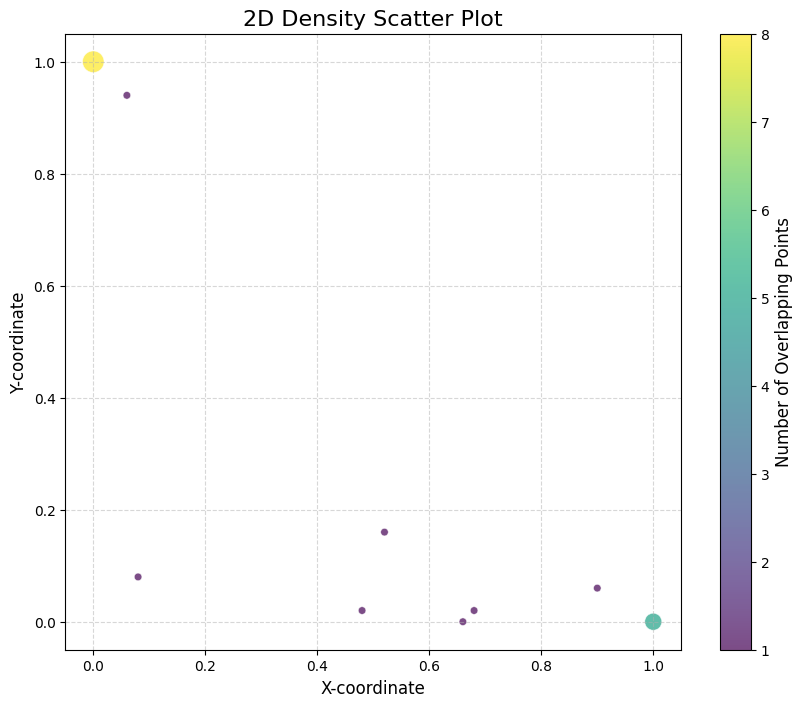

In [71]:
plot_density_dots(res)

In [65]:
summary_results

{'Memory answer': 0.0,
 'Counter answer 1': 1.0,
 'Counter answer 2': 0.0,
 'Distractor answer': 0.0}

In [66]:
answers

['Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records',
 'Stax Records']

1. create 100 samples entity based and 100 samples num/date based - **Done**
2. create distractor paragraphs (for each answer) - **Done**
3. sanity check #1 - ask llm based on memory alone
4. ask with 1 reasoning path and compare between 2 groups (graph will be prob to answer context (softmax with memory, without invalids) vs reasoning chain length)
5. sanity check #2 - ask llm with disconnected reasoning chains
6. qualitive check of the good and bad samples
7. ask with 2 reasoning paths and compare between 2 groups

## Analize:

In [10]:
import plotly.graph_objects as go

# Sample data
x1 = [1, 2, 3, 2, None]
x2 = [None, 2, 2, 3, 1]
y1 = [0.8, 0.5, 0.3, 0.2, 0.7]  # memory
y2 = [0.1, 0.4, 0.6, 0.7, 0.2]  # context 1
y3 = [0.1, 0.1, 0.1, 0.1, 0.1]  # context 2

# Convert None to -1 for plotting
x1 = [v if v is not None else -1 for v in x1]
x2 = [v if v is not None else -1 for v in x2]

fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y1,
    mode='markers', name='Memory',
    marker=dict(size=6, color='red')
))
fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y2,
    mode='markers', name='Context Answer 1',
    marker=dict(size=6, color='green')
))
fig.add_trace(go.Scatter3d(
    x=x1, y=x2, z=y3,
    mode='markers', name='Context Answer 2',
    marker=dict(size=6, color='blue')
))

fig.update_layout(
    scene=dict(
        xaxis_title='x1 (Hops for Context 1)',
        yaxis_title='x2 (Hops for Context 2)',
        zaxis_title='Probability'
    ),
    title='Answer Probability by Reasoning Path Setup',
    height=600,
    showlegend=True
)

fig.show()

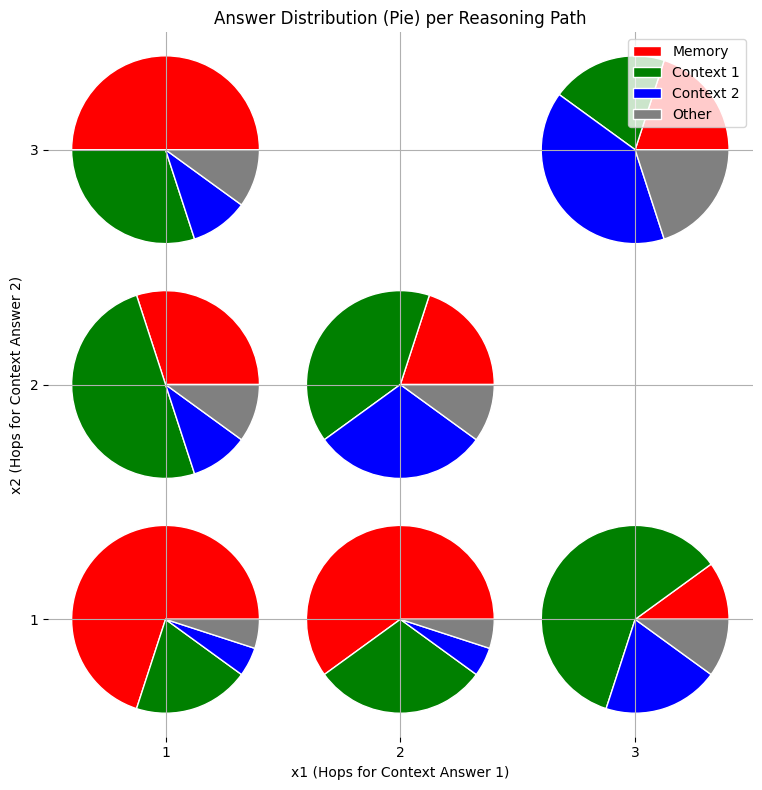

In [20]:
import matplotlib.pyplot as plt
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# Simulated data: (x1, x2, [y1, y2, y3])
data = [
    (1, 1, [0.7, 0.2, 0.05]),   # Mostly memory
    (1, 2, [0.3, 0.5, 0.1]),    # Mostly context 1
    (2, 1, [0.6, 0.3, 0.05]),
    (2, 2, [0.2, 0.4, 0.3]),    # More balanced
    (3, 1, [0.1, 0.6, 0.2]),    # Mostly context 1
    (1, 3, [0.5, 0.3, 0.1]),
    (3, 3, [0.2, 0.2, 0.4]),    # Mostly context 2
]

colors = ['red', 'green', 'blue', 'gray']  # memory, context1, context2, other
pie_radius = 0.4

fig, ax = plt.subplots(figsize=(8, 8))

for x1, x2, probs in data:
    y1, y2, y3 = probs
    y4 = max(0, 1 - (y1 + y2 + y3))  # "Other" answer
    values = [y1, y2, y3, y4]

    # Draw a pie chart at (x1, x2)
    wedges, _ = ax.pie(
        values,
        colors=colors,
        radius=pie_radius,
        center=(x1, x2),
        wedgeprops=dict(width=pie_radius, edgecolor='w')
    )

# Grid setup
ax.set_aspect('equal')
ax.set_xticks(sorted(set(x[0] for x in data)))
ax.set_yticks(sorted(set(x[1] for x in data)))
ax.set_xlim(0.5, 3.5)
ax.set_ylim(0.5, 3.5)
ax.set_xlabel('x1 (Hops for Context Answer 1)')
ax.set_ylabel('x2 (Hops for Context Answer 2)')
ax.set_title('Answer Distribution (Pie) per Reasoning Path')

# Legend
legend_labels = ['Memory', 'Context 1', 'Context 2', 'Other']
legend_patches = [Patch(facecolor=c, edgecolor='w', label=l)
                  for c, l in zip(colors, legend_labels)]
ax.legend(handles=legend_patches, loc='upper right')

plt.grid(True)
plt.tight_layout()
plt.show()


## New Dev:

In [32]:
dev_context = """
Write This Down is a rock band formed in the mid-2000s in Minneapolis, Minnesota. Known for its post-hardcore style, the band gained popularity in the local music scene before signing to a national label. Minneapolis, one of the Twin Cities, lies along the banks of the Mississippi River and has long been a cultural and economic hub of the Upper Midwest.
\n\n
The Mississippi River is one of the major rivers of North America, flowing south from northern Minnesota to the Gulf of Mexico. It served as a critical natural boundary in early U.S. history. The river marked the western edge of the original territory ceded to the United States following the American Revolutionary War.
\n\n
The Treaty of Colombia, signed in 1783, formally ended the Revolutionary War between Great Britain and the thirteen American colonies. As part of the agreement, Great Britain recognized American independence and ceded vast territories to the new nation, extending its western boundary to the Mississippi River.
"""
dev_context1 = """
Write This Down is a rock band formed in the mid-2000s in Minneapolis, Minnesota. Known for its post-hardcore style, the band gained popularity in the local music scene before signing to a national label. Minneapolis, one of the Twin Cities, lies along the banks of the Mississippi River and has long been a cultural and economic hub of the Upper Midwest.
"""
dev_question = "What treaty ceded territory to the US extending west to the body of water by the city where Write This Down was formed?"

prompt = f"""
    You are a logical reasoner. Your task is to answer the question using only the information found in the context below.

    Rules:
    - Do NOT use any external or real-world knowledge.
    - Only rely on statements explicitly made in the context, even if they are factually incorrect.
    - If the context contains contradictions, choose the answer that is best supported by the majority of consistent clues.
    - Your answer must be a single entity or phrase clearly supported by the context.

    Context:
    {dev_context1}

    Question:
    {dev_question}
    """

In [33]:
from knowledge_maze.tools.api_tools import gptAPI
import nest_asyncio
nest_asyncio.apply()

model = gptAPI(prompt,
                  output_format='string',
                  temperature = 1.5,
                  max_concurrent_requests = 100,
                  max_rpm=4900)

answer = model.run('')

In [34]:
answer

'Treaty of Paris 1763'

- try to write explicitly that the answer is **not** the memory answer.
- stirring the model to avoid a certain concept (kfir will send me more info)

## New idea:
- make shortcuts in multi-hop QA datasets. can come from fiddrent paths in the graphs. but have to lead to eather no answer or counter answer.
- change the original to be counter answer also.